In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler

In [2]:
customers = pd.read_csv(
    "../data/raw/customers.csv"
)

static_profile = pd.read_csv(
    "C:/Users/lenovo/Desktop/FinRisk-X/data/processed/customer_financial_profile.csv"
)

enhanced_profile = pd.read_csv(
    "C:/Users/lenovo/Desktop/FinRisk-X/data/processed/enhanced_customer_profile.csv"
)

graph_risk = pd.read_csv(
    "C:/Users/lenovo/Desktop/FinRisk-X/data/processed/customer_graph_risk.csv"
)

transactions = pd.read_csv(
    "C:/Users/lenovo/Desktop/FinRisk-X/data/processed/fraud_transaction_features.csv"
)

transactions["timestamp"] = pd.to_datetime(
    transactions["timestamp"]
)

print("Customers:", customers.shape)
print("Static profile:", static_profile.shape)
print("Enhanced profile:", enhanced_profile.shape)
print("Graph risk:", graph_risk.shape)
print("Transactions:", transactions.shape)

Customers: (10000, 13)
Static profile: (10000, 33)
Enhanced profile: (10000, 23)
Graph risk: (10000, 8)
Transactions: (200000, 23)


In [3]:
for df in [
    customers,
    static_profile,
    enhanced_profile,
    graph_risk,
    transactions
]:
    df["customer_id"] = (
        df["customer_id"]
        .astype(str)
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
    )

In [4]:
print(static_profile["customer_id"].dtype)
print(enhanced_profile["customer_id"].dtype)
print(graph_risk["customer_id"].dtype)

str
str
str


In [5]:
credit_model = joblib.load(
    "../models/credit_risk_xgb.pkl"
)

credit_features = joblib.load(
    "../models/credit_risk_features.pkl"
)

In [6]:
credit_data = static_profile.copy()

credit_probability = credit_model.predict_proba(
    credit_data[credit_features]
)[:, 1]

credit_data["credit_risk_probability"] = credit_probability

credit_data["credit_risk_score"] = (
    credit_data["credit_risk_probability"] * 100
)

In [7]:
credit_data[
    [
        "customer_id",
        "credit_risk_probability",
        "credit_risk_score"
    ]
].head()

,customer_id,credit_risk_probability,credit_risk_score
0,100001,0.393545,39.354542
1,100002,0.665469,66.546906
2,100003,0.515152,51.515221
3,100004,0.411317,41.131725
4,100005,0.573910,57.391029


In [13]:
temporal_model = joblib.load(
    "../models/temporal_risk_model.pkl"
)

temporal_features = joblib.load(
    "../models/temporal_features.pkl"
)

In [9]:
fraud_model = joblib.load(
    "../models/fraud_xgb_model.pkl"
)

fraud_isolation = joblib.load(
    "../models/fraud_isolation_forest.pkl"
)

fraud_scaler = joblib.load(
    "../models/fraud_scaler.pkl"
)

anomaly_scaler = joblib.load(
    "../models/fraud_anomaly_scaler.pkl"
)

fraud_feature_columns = joblib.load(
    "../models/fraud_feature_columns.pkl"
)

In [10]:
fraud_data = transactions.copy()

fraud_data = pd.get_dummies(
    fraud_data,
    columns=[
        "transaction_type",
        "merchant_category"
    ],
    drop_first=False
)

for col in fraud_feature_columns:
    if col not in fraud_data.columns:
        fraud_data[col] = 0

fraud_data = fraud_data[
    fraud_feature_columns
]

In [15]:
# Copy original transaction data
fraud_data = transactions.copy()

# Create the same one-hot encoded columns
fraud_data = pd.get_dummies(
    fraud_data,
    columns=[
        "transaction_type",
        "merchant_category"
    ],
    drop_first=False
)

# Add any columns expected by the trained model
for col in fraud_feature_columns:
    if col not in fraud_data.columns:
        fraud_data[col] = 0

# Remove any columns that were NOT present during training
fraud_data = fraud_data[
    fraud_feature_columns
]

print("Features going into model:", fraud_data.shape)
print("Expected features:", len(fraud_feature_columns))
print("Actual features:", len(fraud_data.columns))

Features going into model: (200000, 23)
Expected features: 23
Actual features: 23


In [21]:
fraud_feature_columns = joblib.load(
    "../models/fraud_feature_columns.pkl"
)

print("Number of saved features:", len(fraud_feature_columns))
print("\nSaved fraud features:")
print(fraud_feature_columns)

Number of saved features: 23

Saved fraud features:
['amount', 'hour', 'day_of_week', 'is_weekend', 'amount_deviation', 'seconds_since_previous', 'transactions_24h', 'spending_24h', 'device_changed', 'transaction_type_ATM', 'transaction_type_Bank Transfer', 'transaction_type_Card', 'transaction_type_Online', 'transaction_type_UPI', 'merchant_category_Electronics', 'merchant_category_Entertainment', 'merchant_category_Financial', 'merchant_category_Food', 'merchant_category_Grocery', 'merchant_category_Healthcare', 'merchant_category_Retail', 'merchant_category_Travel', 'merchant_category_Utilities']


In [22]:
fraud_data = transactions.copy()

fraud_data = pd.get_dummies(
    fraud_data,
    columns=[
        "transaction_type",
        "merchant_category"
    ],
    drop_first=False
)

for col in fraud_feature_columns:
    if col not in fraud_data.columns:
        fraud_data[col] = 0

fraud_data = fraud_data[
    fraud_feature_columns
]

In [23]:
X_fraud_scaled = fraud_scaler.transform(
    fraud_data
)

ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- merchant_category_Electronics
- merchant_category_Entertainment
- merchant_category_Financial
- merchant_category_Food
- merchant_category_Grocery
- ...


In [24]:
print("MODEL FEATURES:")
print(fraud_model.get_booster().feature_names)

print("\nSCALER FEATURES:")
print(fraud_scaler.feature_names_in_)

print("\nSAVED FEATURE COLUMNS:")
print(fraud_feature_columns)

MODEL FEATURES:
['amount', 'hour', 'day_of_week', 'is_weekend', 'amount_deviation', 'seconds_since_previous', 'transactions_24h', 'spending_24h', 'device_changed', 'transaction_type_ATM', 'transaction_type_Bank Transfer', 'transaction_type_Card', 'transaction_type_Online', 'transaction_type_UPI', 'merchant_category_Electronics', 'merchant_category_Entertainment', 'merchant_category_Financial', 'merchant_category_Food', 'merchant_category_Grocery', 'merchant_category_Healthcare', 'merchant_category_Retail', 'merchant_category_Travel', 'merchant_category_Utilities']

SCALER FEATURES:
['amount' 'hour' 'day_of_week' 'is_weekend' 'amount_deviation'
 'seconds_since_previous' 'transactions_24h' 'spending_24h'
 'device_changed']

SAVED FEATURE COLUMNS:
['amount', 'hour', 'day_of_week', 'is_weekend', 'amount_deviation', 'seconds_since_previous', 'transactions_24h', 'spending_24h', 'device_changed', 'transaction_type_ATM', 'transaction_type_Bank Transfer', 'transaction_type_Card', 'transaction_t

In [25]:
# ============================================================
# FRAUD RISK PREDICTION
# ============================================================

fraud_model = joblib.load(
    "../models/fraud_xgb_model.pkl"
)

fraud_isolation = joblib.load(
    "../models/fraud_isolation_forest.pkl"
)

fraud_scaler = joblib.load(
    "../models/fraud_scaler.pkl"
)

anomaly_scaler = joblib.load(
    "../models/fraud_anomaly_scaler.pkl"
)

fraud_feature_columns = joblib.load(
    "../models/fraud_feature_columns.pkl"
)

# ------------------------------------------------------------
# 1. Reconstruct fraud features
# ------------------------------------------------------------

fraud_data = transactions.copy()

fraud_data = pd.get_dummies(
    fraud_data,
    columns=[
        "transaction_type",
        "merchant_category"
    ],
    drop_first=False
)

# Add any missing model features
for col in fraud_feature_columns:
    if col not in fraud_data.columns:
        fraud_data[col] = 0

# Keep EXACT XGBoost feature order
fraud_data = fraud_data[
    fraud_feature_columns
]

print("XGBoost feature shape:", fraud_data.shape)
print("Expected XGBoost features:", len(fraud_feature_columns))


# ------------------------------------------------------------
# 2. XGBoost Fraud Probability
# ------------------------------------------------------------

fraud_probability = fraud_model.predict_proba(
    fraud_data
)[:, 1]

print("Fraud probability generated.")


# ------------------------------------------------------------
# 3. Isolation Forest
# ------------------------------------------------------------

# Isolation Forest was trained using only the numerical features
isolation_features = list(
    fraud_scaler.feature_names_in_
)

print("\nIsolation Forest features:")
print(isolation_features)

isolation_data = fraud_data[
    isolation_features
]

# Scale exactly as during training
X_isolation_scaled = fraud_scaler.transform(
    isolation_data
)

# Isolation Forest anomaly score
raw_anomaly_score = (
    -fraud_isolation.decision_function(
        X_isolation_scaled
    )
)

# Normalize anomaly score
anomaly_score = anomaly_scaler.transform(
    raw_anomaly_score.reshape(-1, 1)
).ravel()

anomaly_score = np.clip(
    anomaly_score,
    0,
    1
)


# ------------------------------------------------------------
# 4. Hybrid Fraud Score
# ------------------------------------------------------------

fraud_hybrid_score = (
    0.70 * fraud_probability
    + 0.30 * anomaly_score
)

fraud_hybrid_score = np.clip(
    fraud_hybrid_score,
    0,
    1
)


# ------------------------------------------------------------
# 5. Store Results
# ------------------------------------------------------------

transactions["fraud_probability"] = (
    fraud_probability
)

transactions["anomaly_score"] = (
    anomaly_score
)

transactions["hybrid_fraud_score"] = (
    fraud_hybrid_score
)


print("\nFraud prediction completed successfully.")

print(
    transactions[
        [
            "customer_id",
            "amount",
            "fraud_probability",
            "anomaly_score",
            "hybrid_fraud_score"
        ]
    ].head()
)

XGBoost feature shape: (200000, 23)
Expected XGBoost features: 23
Fraud probability generated.

Isolation Forest features:
['amount', 'hour', 'day_of_week', 'is_weekend', 'amount_deviation', 'seconds_since_previous', 'transactions_24h', 'spending_24h', 'device_changed']

Fraud prediction completed successfully.
  customer_id    amount  fraud_probability  anomaly_score  hybrid_fraud_score
0      100001  13351.43           0.139046       0.816251            0.342207
1      100001   4474.74           0.187536       0.345164            0.234825
2      100001  11412.17           0.158662       0.490903            0.258335
3      100001   2012.79           0.231766       0.054910            0.178709
4      100001    398.77           0.129241       0.071005            0.111770


In [26]:
# ============================================================
# CUSTOMER-LEVEL FRAUD RISK
# ============================================================

customer_fraud_risk = (
    transactions
    .groupby("customer_id")
    .agg(
        avg_fraud_probability=(
            "fraud_probability",
            "mean"
        ),
        max_fraud_probability=(
            "fraud_probability",
            "max"
        ),
        avg_anomaly_score=(
            "anomaly_score",
            "mean"
        ),
        max_anomaly_score=(
            "anomaly_score",
            "max"
        ),
        avg_hybrid_fraud_score=(
            "hybrid_fraud_score",
            "mean"
        ),
        max_hybrid_fraud_score=(
            "hybrid_fraud_score",
            "max"
        )
    )
    .reset_index()
)

customer_fraud_risk["fraud_risk_score"] = (
    0.60 * customer_fraud_risk[
        "max_hybrid_fraud_score"
    ]
    +
    0.40 * customer_fraud_risk[
        "avg_hybrid_fraud_score"
    ]
) * 100

print(
    customer_fraud_risk.head()
)

print(
    "\nFraud risk score statistics:"
)

print(
    customer_fraud_risk[
        "fraud_risk_score"
    ].describe()
)

  customer_id  avg_fraud_probability  max_fraud_probability  \
0      100001               0.262764               0.783083   
1      100002               0.313527               0.803767   
2      100003               0.476873               0.783061   
3      100004               0.266366               0.797005   
4      100005               0.295973               0.812917   

   avg_anomaly_score  max_anomaly_score  avg_hybrid_fraud_score  \
0           0.185125           0.816251                0.239472   
1           0.221139           0.709282                0.285810   
2           0.261322           0.502814                0.412207   
3           0.227899           0.488348                0.254826   
4           0.247687           0.494577                0.281487   

   max_hybrid_fraud_score  fraud_risk_score  
0                0.693558         51.192378  
1                0.620303         48.650618  
2                0.614310         53.346915  
3                0.633866         

In [27]:
# ============================================================
# FINANCIAL HEALTH RISK
# ============================================================

health_data = static_profile[
    [
        "customer_id",
        "financial_health_score"
    ]
].copy()

health_data["financial_health_risk_score"] = (
    100 - health_data["financial_health_score"]
)

print(health_data.head())

print("\nFinancial health risk statistics:")
print(
    health_data[
        "financial_health_risk_score"
    ].describe()
)

  customer_id  financial_health_score  financial_health_risk_score
0      100001               64.975851                    35.024149
1      100002               65.109057                    34.890943
2      100003               55.265966                    44.734034
3      100004               70.999953                    29.000047
4      100005               56.226856                    43.773144

Financial health risk statistics:
count    10000.000000
mean        37.340461
std          6.445791
min         12.382306
25%         32.854107
50%         37.224039
75%         41.620702
max         62.727903
Name: financial_health_risk_score, dtype: float64


In [28]:
# ============================================================
# GRAPH RISK
# ============================================================

graph_data = graph_risk[
    [
        "customer_id",
        "graph_risk_score"
    ]
].copy()

print(graph_data.head())

print("\nGraph risk statistics:")
print(
    graph_data[
        "graph_risk_score"
    ].describe()
)

  customer_id  graph_risk_score
0      104311         76.601382
1      103181         74.314516
2      103557         72.926267
3      109288         71.612903
4      109254         71.612903

Graph risk statistics:
count    10000.000000
mean        25.663163
std         10.913135
min          0.000000
25%         16.774194
50%         26.394009
75%         31.718093
max         76.601382
Name: graph_risk_score, dtype: float64


In [31]:
# ============================================================
# RECREATE TEMPORAL RISK DATA
# ============================================================

temporal_model = joblib.load(
    "../models/temporal_risk_model.pkl"
)

temporal_features = joblib.load(
    "../models/temporal_features.pkl"
)

temporal_probability = temporal_model.predict_proba(
    enhanced_profile[temporal_features]
)[:, 1]

temporal_data = enhanced_profile[
    ["customer_id"]
].copy()

temporal_data["temporal_risk_probability"] = (
    temporal_probability
)

temporal_data["temporal_risk_score"] = (
    temporal_probability * 100
)

print("Temporal risk data recreated successfully.")

print(
    temporal_data.head()
)

print(
    "\nShape:",
    temporal_data.shape
)

Temporal risk data recreated successfully.
  customer_id  temporal_risk_probability  temporal_risk_score
0      100001                   0.351935            35.193508
1      100002                   0.315314            31.531355
2      100003                   0.410704            41.070427
3      100004                   0.357690            35.768967
4      100005                   0.325702            32.570225

Shape: (10000, 3)


In [32]:
# ============================================================
# RISK FUSION DATASET
# ============================================================

risk_fusion = credit_data[
    [
        "customer_id",
        "credit_risk_probability",
        "credit_risk_score"
    ]
].copy()


# Add temporal risk
risk_fusion = risk_fusion.merge(
    temporal_data[
        [
            "customer_id",
            "temporal_risk_probability",
            "temporal_risk_score"
        ]
    ],
    on="customer_id",
    how="left"
)


# Add fraud risk
risk_fusion = risk_fusion.merge(
    customer_fraud_risk[
        [
            "customer_id",
            "avg_fraud_probability",
            "max_fraud_probability",
            "avg_anomaly_score",
            "max_anomaly_score",
            "avg_hybrid_fraud_score",
            "max_hybrid_fraud_score",
            "fraud_risk_score"
        ]
    ],
    on="customer_id",
    how="left"
)


# Add graph risk
risk_fusion = risk_fusion.merge(
    graph_data,
    on="customer_id",
    how="left"
)


# Add financial health risk
risk_fusion = risk_fusion.merge(
    health_data,
    on="customer_id",
    how="left"
)


print("Risk fusion shape:", risk_fusion.shape)

print("\nColumns:")
print(risk_fusion.columns.tolist())

risk_fusion.head()

Risk fusion shape: (10000, 15)

Columns:
['customer_id', 'credit_risk_probability', 'credit_risk_score', 'temporal_risk_probability', 'temporal_risk_score', 'avg_fraud_probability', 'max_fraud_probability', 'avg_anomaly_score', 'max_anomaly_score', 'avg_hybrid_fraud_score', 'max_hybrid_fraud_score', 'fraud_risk_score', 'graph_risk_score', 'financial_health_score', 'financial_health_risk_score']


,customer_id,credit_risk_probability,credit_risk_score,temporal_risk_probability,temporal_risk_score,avg_fraud_probability,max_fraud_probability,avg_anomaly_score,max_anomaly_score,avg_hybrid_fraud_score,max_hybrid_fraud_score,fraud_risk_score,graph_risk_score,financial_health_score,financial_health_risk_score
0,100001,0.393545,39.354542,0.351935,35.193508,0.262764,0.783083,0.185125,0.816251,0.239472,0.693558,51.192378,20.645161,64.975851,35.024149
1,100002,0.665469,66.546906,0.315314,31.531355,0.313527,0.803767,0.221139,0.709282,0.285810,0.620303,48.650618,29.582111,65.109057,34.890943
2,100003,0.515152,51.515221,0.410704,41.070427,0.476873,0.783061,0.261322,0.502814,0.412207,0.614310,53.346915,27.661290,55.265966,44.734034
3,100004,0.411317,41.131725,0.357690,35.768967,0.266366,0.797005,0.227899,0.488348,0.254826,0.633866,48.225006,41.500701,70.999953,29.000047
4,100005,0.573910,57.391029,0.325702,32.570225,0.295973,0.812917,0.247687,0.494577,0.281487,0.702518,53.410559,12.903226,56.226856,43.773144


In [33]:
# ============================================================
# HANDLE MISSING RISK COMPONENTS
# ============================================================

risk_columns = [
    "credit_risk_score",
    "temporal_risk_score",
    "fraud_risk_score",
    "graph_risk_score",
    "financial_health_risk_score"
]

risk_fusion[risk_columns] = (
    risk_fusion[risk_columns]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

print(
    "Missing values in risk components:"
)

print(
    risk_fusion[
        risk_columns
    ].isna().sum()
)

Missing values in risk components:
credit_risk_score              0
temporal_risk_score            0
fraud_risk_score               0
graph_risk_score               0
financial_health_risk_score    0
dtype: int64


In [35]:
# ============================================================
# FINRISK-X SCORE
# ============================================================

risk_weights = {
    "credit": 0.30,
    "temporal": 0.20,
    "fraud": 0.25,
    "graph": 0.15,
    "financial_health": 0.10
}

risk_fusion["finrisk_score"] = (
    risk_weights["credit"]
    * risk_fusion["credit_risk_score"]
    
    + risk_weights["temporal"]
    * risk_fusion["temporal_risk_score"]
    
    + risk_weights["fraud"]
    * risk_fusion["fraud_risk_score"]
    
    + risk_weights["graph"]
    * risk_fusion["graph_risk_score"]
    
    + risk_weights["financial_health"]
    * risk_fusion["financial_health_risk_score"]
)

risk_fusion["finrisk_score"] = (
    risk_fusion["finrisk_score"]
    .clip(0, 100)
)

print(
    risk_fusion[
        [
            "customer_id",
            "credit_risk_score",
            "temporal_risk_score",
            "fraud_risk_score",
            "graph_risk_score",
            "financial_health_risk_score",
            "finrisk_score"
        ]
    ].head(10)
)

  customer_id  credit_risk_score  temporal_risk_score  fraud_risk_score  \
0      100001          39.354542            35.193508         51.192378   
1      100002          66.546906            31.531355         48.650618   
2      100003          51.515221            41.070427         53.346915   
3      100004          41.131725            35.768967         48.225006   
4      100005          57.391029            32.570225         53.410559   
5      100006          25.429562            30.744440         52.898390   
6      100007          35.942204            27.870321         52.425427   
7      100008          29.676256            30.338964         51.426407   
8      100009          55.407860            46.838020         52.869505   
9      100010          43.426174            38.219109         48.898099   

   graph_risk_score  financial_health_risk_score  finrisk_score  
0         20.645161                    35.024149      38.242348  
1         29.582111                    34.

In [36]:
# ============================================================
# RISK CATEGORIES
# ============================================================

risk_fusion["risk_category"] = pd.cut(
    risk_fusion["finrisk_score"],
    bins=[
        -np.inf,
        25,
        50,
        75,
        np.inf
    ],
    labels=[
        "Low",
        "Moderate",
        "High",
        "Critical"
    ]
)

print(
    risk_fusion[
        "risk_category"
    ].value_counts()
    .sort_index()
)

risk_category
Low          122
Moderate    9284
High         594
Critical       0
Name: count, dtype: int64


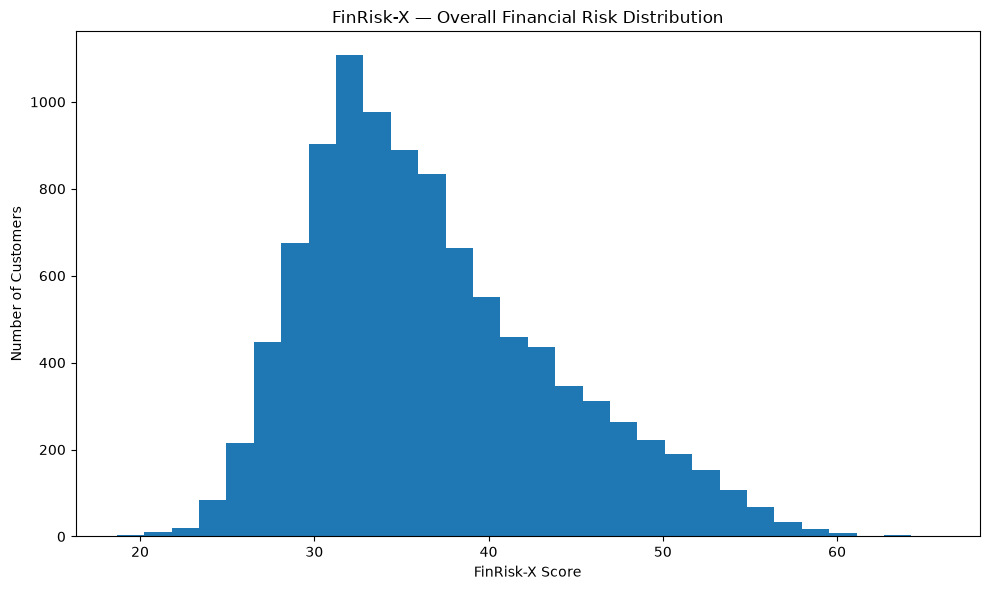

In [37]:
# ============================================================
# RISK DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 6))

plt.hist(
    risk_fusion["finrisk_score"],
    bins=30
)

plt.xlabel("FinRisk-X Score")
plt.ylabel("Number of Customers")
plt.title(
    "FinRisk-X — Overall Financial Risk Distribution"
)

plt.tight_layout()

plt.show()

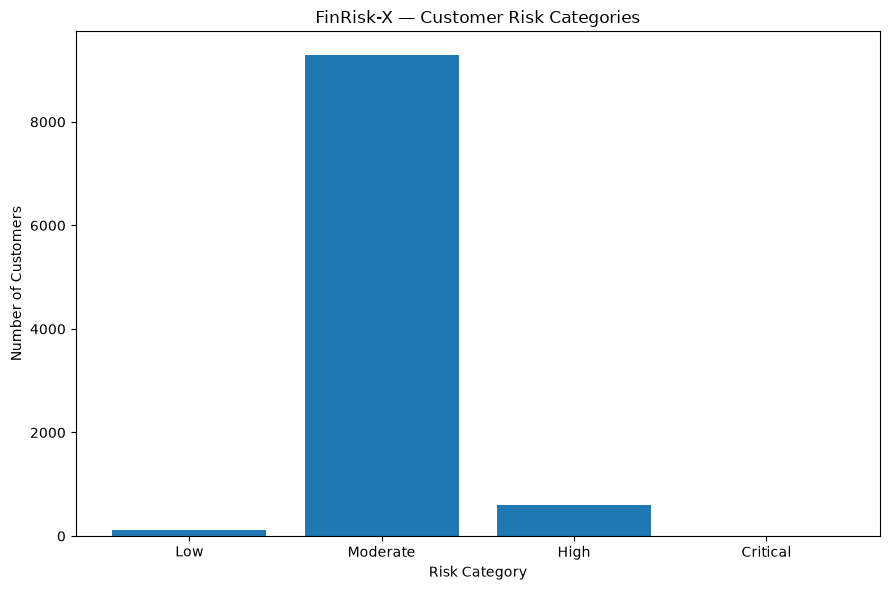

In [38]:
# ============================================================
# RISK CATEGORY DISTRIBUTION
# ============================================================

category_counts = (
    risk_fusion["risk_category"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(9, 6))

plt.bar(
    category_counts.index.astype(str),
    category_counts.values
)

plt.xlabel("Risk Category")
plt.ylabel("Number of Customers")
plt.title(
    "FinRisk-X — Customer Risk Categories"
)

plt.tight_layout()

plt.show()

In [39]:
# ============================================================
# TOP HIGH-RISK CUSTOMERS
# ============================================================

top_risk_customers = (
    risk_fusion
    .sort_values(
        "finrisk_score",
        ascending=False
    )
    .head(20)
)

top_risk_customers[
    [
        "customer_id",
        "finrisk_score",
        "risk_category",
        "credit_risk_score",
        "temporal_risk_score",
        "fraud_risk_score",
        "graph_risk_score",
        "financial_health_risk_score"
    ]
]

,customer_id,finrisk_score,risk_category,credit_risk_score,temporal_risk_score,fraud_risk_score,graph_risk_score,financial_health_risk_score
5955,105956,65.841460,High,95.635399,45.931347,50.978506,65.483871,53.973608
838,100839,65.587404,High,89.988571,44.697506,68.195970,50.060484,50.932655
6034,106035,63.618758,High,79.443413,56.462116,70.102382,47.610887,38.260791
3844,103845,63.520300,High,95.862587,42.861958,66.639838,32.225806,46.953002
6811,106812,63.079253,High,89.494598,52.173389,55.394384,52.983871,40.000180
6586,106587,61.655123,High,89.991791,39.306625,64.750420,41.028226,44.544198
6136,106137,61.197942,High,90.935722,43.719753,57.289554,41.612903,46.089488
1279,101280,60.641373,High,89.299011,41.821999,54.737074,55.090726,35.393890
7337,107338,60.501148,High,86.435265,57.702774,59.087122,26.491935,42.844427
2480,102481,60.153256,High,75.900345,42.512524,58.137469,64.142615,47.248870


In [40]:
# ============================================================
# SAVE FINAL RISK SCORES
# ============================================================

risk_fusion.to_csv(
    "../data/processed/final_risk_scores.csv",
    index=False
)

joblib.dump(
    risk_weights,
    "../models/risk_fusion_config.pkl"
)

print("Final risk scores saved successfully.")

print(
    "CSV:",
    "../data/processed/final_risk_scores.csv"
)

print(
    "Config:",
    "../models/risk_fusion_config.pkl"
)

Final risk scores saved successfully.
CSV: ../data/processed/final_risk_scores.csv
Config: ../models/risk_fusion_config.pkl


In [41]:
# ============================================================
# PHASE 10 VALIDATION
# ============================================================

print("=" * 60)
print("FinRisk-X — Phase 10 Validation")
print("=" * 60)

print("\nCustomers:", len(risk_fusion))

print(
    "Unique customers:",
    risk_fusion["customer_id"].nunique()
)

print(
    "\nFinRisk score range:"
)

print(
    risk_fusion["finrisk_score"].min(),
    "to",
    risk_fusion["finrisk_score"].max()
)

print("\nRisk categories:")
print(
    risk_fusion[
        "risk_category"
    ].value_counts()
    .sort_index()
)

print("\nMissing values:")
print(
    risk_fusion[
        [
            "credit_risk_score",
            "temporal_risk_score",
            "fraud_risk_score",
            "graph_risk_score",
            "financial_health_risk_score",
            "finrisk_score"
        ]
    ].isna().sum()
)

print("\n" + "=" * 60)
print("PHASE 10 COMPLETE")
print("=" * 60)

FinRisk-X — Phase 10 Validation

Customers: 10000
Unique customers: 10000

FinRisk score range:
18.663046458338297 to 65.84146005311649

Risk categories:
risk_category
Low          122
Moderate    9284
High         594
Critical       0
Name: count, dtype: int64

Missing values:
credit_risk_score              0
temporal_risk_score            0
fraud_risk_score               0
graph_risk_score               0
financial_health_risk_score    0
finrisk_score                  0
dtype: int64

PHASE 10 COMPLETE
